# CMP6202 – Notebook 03: Evaluation design and model development

Evidence for report sections **3.2**, **4.1** and **4.2**. Eight classifiers from the module (Decision Tree, Random
Forest, Gaussian Naive Bayes, k-Nearest Neighbours, Logistic Regression, SVM, Gradient Boosting, MLP) are scored with
default settings, tuned, and evaluated by cross-validation on the **training set only**.

In [1]:
# Google Colab setup. On a local machine this cell does nothing.
# On Colab: upload the project folder to Google Drive (README, "Run on Google Colab"). The cell mounts Drive,
# finds the folder, installs the pinned libraries and makes `nids` importable.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    from importlib.metadata import version

    from google.colab import drive

    drive.mount("/content/drive")
    # I accept both upload locations the README describes and pick the one that holds the nids package.
    candidates = ["/content/drive/MyDrive/CMP6202_NIDS/Project", "/content/drive/MyDrive/Project"]
    found = [path for path in candidates if os.path.isdir(os.path.join(path, "src", "nids"))]
    if not found:
        raise SystemExit(f"Project folder not found on Drive; looked in {candidates}")
    PROJECT_DIR = found[0]
    os.chdir(PROJECT_DIR)
    loaded = {name: version(dist) for name, dist in (("numpy", "numpy"), ("pandas", "pandas"), ("sklearn", "scikit-learn"))
              if name in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
    changed = [name for name, old in loaded.items()
               if old != version({"sklearn": "scikit-learn"}.get(name, name))]
    if changed:
        # A library that was already imported cannot be replaced in a running session.
        raise SystemExit(f"Upgraded {changed}: choose Runtime > Restart session, then run this cell again.")
    print("Running on Colab from", PROJECT_DIR)
else:
    print("Running locally; Colab setup skipped")

Running locally; Colab setup skipped


## **Import the libraries and load the training set**

In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from nids import config, data, evaluation, features, models, plotting, report_numbers  # my package: src/nids

# Searches are cached in models/; set NIDS_FORCE_RETRAIN=1 to retrain everything (several hours on Colab).
FORCE_RETRAIN = os.environ.get("NIDS_FORCE_RETRAIN") == "1"
plotting.apply_style()

sample = data.load_sample()
split = data.load_split(sample)  # the split saved by notebook 02
data.assert_no_leakage(split)
X_train, y_train = split.X_train, split.y_train
y_train.value_counts()

Label
Benign            50857
SSH-Bruteforce     9106
FTP-BruteForce       37
Name: count, dtype: int64

# 3 Experimental Design
## 3.2 Identification of appropriate evaluation techniques

Why `StratifiedKFold` (Week 7, 2024 slides): how many FTP flows each validation fold receives, and how much a default Decision
Tree's macro F1 varies, with plain and stratified 5-fold cross-validation.

In [3]:
composition = evaluation.fold_composition(y_train)
composition.to_csv(config.TABLES_DIR / "3_2_fold_composition.csv")
display(composition)

tree_default = features.build_pipeline(X_train, models.default_estimators()[models.TREE])
splitter_table = evaluation.splitter_scores(tree_default, X_train, y_train)
splitter_table.round(6).to_csv(config.TABLES_DIR / "3_2_kfold_vs_stratified.csv", index=False)
splitter_table.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,min,max
KFold (no shuffle),4,11,10,7,5,4,11
KFold (shuffled),7,8,9,4,9,4,9
StratifiedKFold (shuffled),7,7,7,8,8,7,8


,splitter,metric,mean,std,per_fold
0,KFold (shuffled),accuracy,0.9999,0.0001,"0.9999, 1.0000, 0.9998, 0.9998, 0.9999"
1,KFold (shuffled),f1_macro,0.9964,0.0070,"0.9999, 1.0000, 0.9998, 0.9997, 0.9824"
2,StratifiedKFold (shuffled),accuracy,0.9999,0.0001,"0.9997, 1.0000, 1.0000, 0.9998, 0.9999"
3,StratifiedKFold (shuffled),f1_macro,0.9954,0.0090,"0.9774, 1.0000, 1.0000, 0.9998, 0.9999"


# 4 Predictive Modelling / Model Development
## 4.1 The predictive modelling process

**Encoding and scaling (Weeks 3–4 labs).** The target is label-encoded; `Protocol` is one-hot encoded inside the
pipeline. The plot compares `StandardScaler` and `MinMaxScaler` on one heavy-tailed feature.

,class,code
0,Benign,0
1,FTP-BruteForce,1
2,SSH-Bruteforce,2


MinMax on Flow Byts/s: median 0.000006, 99th percentile 0.002370


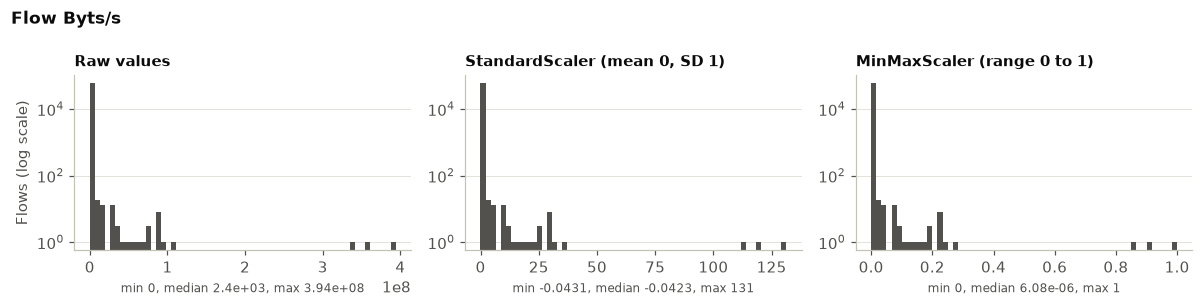

In [4]:
label_encoder = LabelEncoder().fit(y_train)
display(pd.DataFrame({"class": label_encoder.classes_, "code": range(len(label_encoder.classes_))}))

column = "Flow Byts/s"
standard = StandardScaler().fit_transform(X_train[[column]]).ravel()
minmax = MinMaxScaler().fit_transform(X_train[[column]]).ravel()
fig = plotting.plot_scaling_comparison(X_train[column], standard, minmax)
plotting.save_figure(fig, "4_1_scaling_comparison")
print(f"MinMax on {column}: median {np.median(minmax):.6f}, 99th percentile {np.percentile(minmax, 99):.6f}")

**Do trees need scaling? (Week 6 lab.)** I train the same Decision Tree on raw and on standardised features of one
training fold and compare their validation predictions.

In [5]:
_, numeric_cols = features.model_columns(X_train)
fold_train, fold_valid = next(models.cv_splitter().split(X_train, y_train))
X_fit, X_val = X_train.iloc[fold_train][numeric_cols], X_train.iloc[fold_valid][numeric_cols]
y_fit = y_train.iloc[fold_train]

scaler = StandardScaler().fit(X_fit)  # fitted on the training fold only
raw_tree = DecisionTreeClassifier(random_state=config.SEED).fit(X_fit, y_fit)
scaled_tree = DecisionTreeClassifier(random_state=config.SEED).fit(scaler.transform(X_fit), y_fit)
same = (raw_tree.predict(X_val) == scaled_tree.predict(scaler.transform(X_val))).mean()
print(f"Same prediction from raw and standardised tree: {same:.4%} of {len(X_val):,} validation flows")

Same prediction from raw and standardised tree: 100.0000% of 12,000 validation flows


**The pipeline.** Preprocessing → SMOTE → classifier in one imbalanced-learn `Pipeline` (Weeks 2 and 4), so scaling
and SMOTE are refitted on each training fold and never see validation data.

In [6]:
pipe = features.build_pipeline(X_train, models.default_estimators()[models.TREE], sampler=models.make_smote())
pipe

,steps,"[('preprocess', ...), ('resample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('protocol', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"t

### Baseline models: default settings, no SMOTE

In [7]:
defaults = models.default_estimators()
shown = ("C", "kernel", "gamma", "max_iter", "solver", "criterion", "max_depth", "min_samples_leaf", "n_estimators",
         "max_features", "n_neighbors", "weights", "var_smoothing", "learning_rate", "hidden_layer_sizes",
         "activation", "alpha")
default_params = pd.DataFrame({name: {k: v for k, v in est.get_params().items() if k in shown}
                               for name, est in defaults.items()}).T
display(default_params.fillna("–"))

baseline = {}
for name in models.MODEL_NAMES:
    start = time.perf_counter()
    # Default Gradient Boosting predicts no FTP flow in some folds, so FTP precision is undefined there and scored 0
    # (its baseline FTP recall is 0.62); the tuned pipeline with SMOTE finds every FTP flow (section 4.2).
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UndefinedMetricWarning)
        baseline[name] = models.baseline_cv(name, X_train, y_train)  # cross_validate on the same 5 folds
    print(f"{name:24s} baseline CV in {time.perf_counter() - start:6.1f} s")

,C,max_iter,solver,criterion,max_depth,max_features,min_samples_leaf,n_estimators,n_neighbors,weights,var_smoothing,gamma,kernel,learning_rate,activation,alpha,hidden_layer_sizes
Logistic Regression,1.0,2000,lbfgs,–,–,–,–,–,–,–,–,–,–,–,–,–,–
Decision Tree,–,–,–,gini,–,–,1,–,–,–,–,–,–,–,–,–,–
Random Forest,–,–,–,gini,–,sqrt,1,100,–,–,–,–,–,–,–,–,–
k-Nearest Neighbours,–,–,–,–,–,–,–,–,5,uniform,–,–,–,–,–,–,–
Gaussian Naive Bayes,–,–,–,–,–,–,–,–,–,–,0.0,–,–,–,–,–,–
Support Vector Machine,1.0,1000000,–,–,–,–,–,–,–,–,–,scale,rbf,–,–,–,–
Gradient Boosting,–,100.0,–,–,–,1.0,20.0,–,–,–,–,–,–,0.1,–,–,–
Multi-layer Perceptron,–,500,adam,–,–,–,–,–,–,–,–,–,–,constant,relu,0.0001,"(100,)"


Decision Tree            baseline CV in    1.5 s


Random Forest            baseline CV in    6.3 s


Gaussian Naive Bayes     baseline CV in    1.2 s


k-Nearest Neighbours     baseline CV in   12.0 s


Logistic Regression      baseline CV in    2.0 s


Support Vector Machine   baseline CV in    2.7 s


Gradient Boosting        baseline CV in    5.2 s


Multi-layer Perceptron   baseline CV in    3.1 s


### Hyper-parameter tuning: `RandomizedSearchCV` (Week 10, 2024 slides)

20 settings × 5 stratified folds per model; the SMOTE target and neighbours are searched with the model parameters,
and the best mean weighted F1 is refitted on all training flows.

In [8]:
def readable(value):
    # Short labels for the search-space table: transformer objects and SMOTE targets print badly as they are.
    if callable(getattr(value, "func", None)):
        return "symlog"
    if isinstance(value, dict):
        return f"{next(iter(value.values())):,} FTP flows"
    if isinstance(value, (StandardScaler, MinMaxScaler)):
        return type(value).__name__
    return round(value, 4) if isinstance(value, float) else value


def label(param):
    return (param.replace("model__", "").replace("resample__", "SMOTE ")
                 .replace("preprocess__numeric__log", "numeric transform")
                 .replace("preprocess__numeric__scale", "scaler"))


space_table = pd.DataFrame([
    {"model": name, "parameter": label(param),
     "values searched": (f"{dist.dist.name}({dist.args[0]:g}, {dist.args[1]:g})" if hasattr(dist, "dist")
                         else ", ".join(str(readable(v)) for v in dist))}
    for name, space in models.search_spaces().items() for param, dist in space.items()
])
space_table.to_csv(config.TABLES_DIR / "4_1_search_spaces.csv", index=False)
space_table

,model,parameter,values searched
0,Logistic Regression,C,"loguniform(0.001, 100)"
1,Logistic Regression,numeric transform,"passthrough, symlog"
2,Logistic Regression,SMOTE sampling_strategy,"500 FTP flows, 1,000 FTP flows, 2,000 FTP flows"
3,Logistic Regression,SMOTE k_neighbors,"3, 5"
4,Decision Tree,max_depth,"None, 5, 10, 15, 20, 30"
5,Decision Tree,min_samples_leaf,"randint(1, 30)"
6,Decision Tree,criterion,"gini, entropy"
7,Decision Tree,SMOTE sampling_strategy,"500 FTP flows, 1,000 FTP flows, 2,000 FTP flows"
8,Decision Tree,SMOTE k_neighbors,"3, 5"
9,Random Forest,n_estimators,"randint(100, 401)"


In [9]:
# RandomizedSearchCV(pipeline, search_spaces()[name], n_iter=20, cv=StratifiedKFold(5), refit="f1_weighted"),
# cached in models/ so the notebook re-runs in minutes (models.load_or_run_search).
runs = {}
for name in models.MODEL_NAMES:
    start = time.perf_counter()
    runs[name] = models.load_or_run_search(name, X_train, y_train, force=FORCE_RETRAIN)
    source = "trained now" if time.perf_counter() - start > 5 else "loaded from cache"
    print(f"{name:24s} {source}; the search took {runs[name].search_seconds:6.1f} s when it ran")

best_params = pd.DataFrame([
    {"model": name, "parameter": label(k), "selected value": readable(v)}
    for name, run in runs.items() for k, v in run.search.best_params_.items()
])
best_params.to_csv(config.TABLES_DIR / "4_1_best_params.csv", index=False)
best_params

Decision Tree            loaded from cache; the search took   20.4 s when it ran
Random Forest            loaded from cache; the search took  176.3 s when it ran
Gaussian Naive Bayes     loaded from cache; the search took   17.6 s when it ran
k-Nearest Neighbours     loaded from cache; the search took  569.8 s when it ran
Logistic Regression      loaded from cache; the search took   30.2 s when it ran
Support Vector Machine   loaded from cache; the search took  152.7 s when it ran
Gradient Boosting        loaded from cache; the search took  109.8 s when it ran
Multi-layer Perceptron   loaded from cache; the search took   71.3 s when it ran


,model,parameter,selected value
0,Decision Tree,criterion,entropy
1,Decision Tree,max_depth,None
2,Decision Tree,min_samples_leaf,4
3,Decision Tree,SMOTE k_neighbors,5
4,Decision Tree,SMOTE sampling_strategy,"1,000 FTP flows"
5,Random Forest,max_depth,20
6,Random Forest,max_features,log2
7,Random Forest,min_samples_leaf,1
8,Random Forest,n_estimators,113
9,Random Forest,SMOTE k_neighbors,5


,model,search_seconds,fit_seconds,predict_ms_per_1000
0,Decision Tree,20.354,0.472,0.369
1,Random Forest,176.268,3.764,2.707
2,Gaussian Naive Bayes,17.618,0.325,1.004
3,k-Nearest Neighbours,569.822,0.266,32.728
4,Logistic Regression,30.209,0.778,1.234
5,Support Vector Machine,152.750,0.673,2.098
6,Gradient Boosting,109.831,4.096,9.461
7,Multi-layer Perceptron,71.298,7.026,1.657


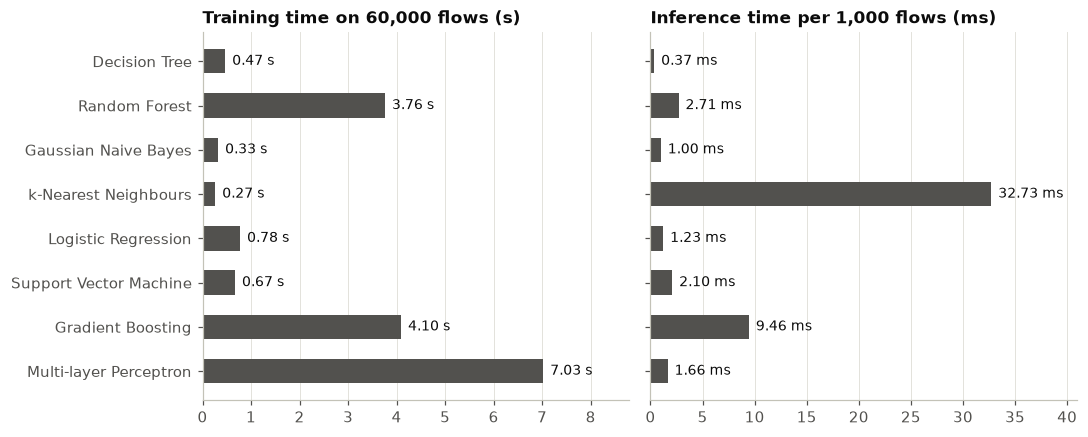

In [10]:
timing = pd.DataFrame([
    {"model": name, "search_seconds": run.search_seconds, "fit_seconds": run.fit_seconds,
     "predict_ms_per_1000": run.predict_ms_per_1000}
    for name, run in runs.items()
])
timing.round(4).to_csv(config.TABLES_DIR / "4_1_timing.csv", index=False)
fig = plotting.plot_timing(timing)
plotting.save_figure(fig, "4_1_training_inference_time")
timing.round(3)

**Grid search versus randomised search (Week 10, 2024 slides)** for the Decision Tree, over the same ranges.

In [11]:
grid, grid_seconds = models.load_or_run_grid_search(X_train, y_train, force=FORCE_RETRAIN)


def search_row(name, search, seconds):
    settings = len(search.cv_results_["params"])
    return {"search": name, "settings": settings, "fits": settings * config.CV_FOLDS, "seconds": seconds,
            "best weighted F1": search.best_score_,
            "best macro F1 of any setting": search.cv_results_["mean_test_f1_macro"].max()}


tree_run = runs[models.TREE]
grid_vs_random = pd.DataFrame([search_row("RandomizedSearchCV", tree_run.search, tree_run.search_seconds),
                               search_row("GridSearchCV", grid, grid_seconds)]).set_index("search")
grid_vs_random.round(6).to_csv(config.TABLES_DIR / "4_1_grid_vs_random.csv")
print("Grid search best setting:", {label(k): readable(v) for k, v in grid.best_params_.items()})
grid_vs_random.round(5)

Grid search best setting: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5, 'SMOTE k_neighbors': 3, 'SMOTE sampling_strategy': '500 FTP flows'}


,settings,fits,seconds,best weighted F1,best macro F1 of any setting
search,,,,,
RandomizedSearchCV,20,100,20.35396,0.99985,0.99534
GridSearchCV,432,2160,493.88607,0.99987,0.99540


**How decisive was weighted F1?** For each model, how many of the 20 settings scored within one standard deviation
of the best, and how far apart their macro F1 is.

In [12]:
ties = []
for name, run in runs.items():
    res, best = run.search.cv_results_, run.search.best_index_
    best_mean, best_std = res["mean_test_f1_weighted"][best], res["std_test_f1_weighted"][best]
    within = res["mean_test_f1_weighted"] >= best_mean - best_std
    macro = res["mean_test_f1_macro"]
    ties.append({"model": name, "best weighted F1": best_mean, "settings within 1 SD": int(within.sum()),
                 "macro F1 range among them": f"{macro[within].min():.4f}–{macro[within].max():.4f}",
                 "best macro F1 of all settings": macro.max()})
ties = pd.DataFrame(ties)
ties.to_csv(config.TABLES_DIR / "4_1_selection_ties.csv", index=False)
ties.round(5)

,model,best weighted F1,settings within 1 SD,macro F1 range among them,best macro F1 of all settings
0,Decision Tree,0.99985,6,0.9663–0.9953,0.99534
1,Random Forest,0.99993,13,0.9954–0.9955,0.99549
2,Gaussian Naive Bayes,0.99963,5,0.9993–0.9995,0.99952
3,k-Nearest Neighbours,0.99998,6,0.9955–1.0000,0.99998
4,Logistic Regression,0.99985,7,0.9525–0.9837,0.98368
5,Support Vector Machine,0.99992,11,0.9876–0.9955,0.99547
6,Gradient Boosting,0.99995,16,0.9904–0.9955,0.99551
7,Multi-layer Perceptron,0.99989,10,0.9758–0.9953,0.99534


## 4.2 Evaluation results on "seen" data

Cross-validated scores of the tuned models, compared with the baselines, and the gap between training and
validation folds (over-fitting check, Week 2).

metric                 f1_macro         f1_weighted         recall_ftp        
stage                  Baseline   Tuned    Baseline   Tuned   Baseline   Tuned
model                                                                         
Decision Tree            0.9954  0.9903      0.9999  0.9999     1.0000  0.9714
Random Forest            0.9955  0.9955      0.9999  0.9999     1.0000  1.0000
Gaussian Naive Bayes     0.9990  0.9995      0.9992  0.9996     1.0000  1.0000
k-Nearest Neighbours     0.9915  1.0000      0.9999  1.0000     1.0000  1.0000
Logistic Regression      0.9718  0.9793      0.9998  0.9999     1.0000  1.0000
Support Vector Machine   0.9905  0.9955      0.9996  0.9999     0.9714  1.0000
Gradient Boosting        0.8833  0.9955      0.9994  1.0000     0.6214  1.0000
Multi-layer Perceptron   0.9999  0.9876      0.9999  0.9999     1.0000  1.0000

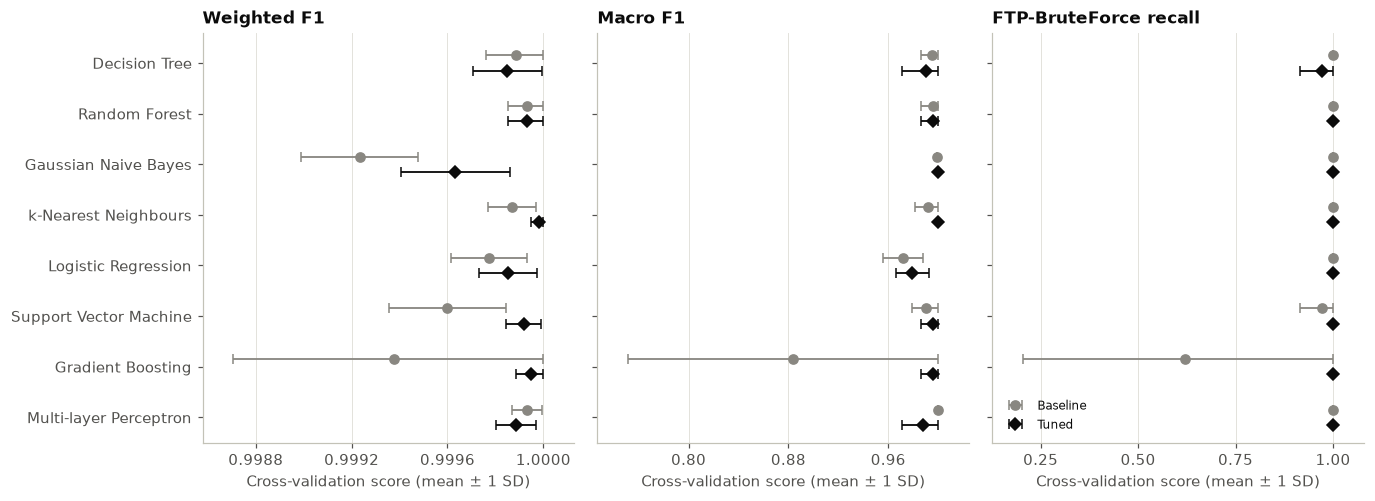

In [13]:
summaries = {name: models.best_cv_summary(run) for name, run in runs.items()}
summary_table = pd.concat(summaries, names=["model", "metric"]).round(4)
summary_table.to_csv(config.TABLES_DIR / "4_2_cv_summary.csv")

metrics_shown = {"f1_weighted": "Weighted F1", "f1_macro": "Macro F1", "recall_ftp": "FTP-BruteForce recall"}
rows = []
for name in models.MODEL_NAMES:
    for metric in metrics_shown:
        rows.append({"model": name, "stage": "Baseline", "metric": metric,
                     "mean": baseline[name][f"test_{metric}"].mean(), "std": baseline[name][f"test_{metric}"].std(ddof=0)})
        s = summaries[name].loc[metric]
        rows.append({"model": name, "stage": "Tuned", "metric": metric,
                     "mean": s["validation_mean"], "std": s["validation_std"]})
comparison = pd.DataFrame(rows)
comparison.round(5).to_csv(config.TABLES_DIR / "4_2_baseline_vs_tuned.csv", index=False)
fig = plotting.plot_cv_comparison(comparison, metrics_shown)
plotting.save_figure(fig, "4_2_cv_baseline_vs_tuned")
comparison.pivot_table(index="model", columns=["metric", "stage"], values="mean").reindex(models.MODEL_NAMES).round(4)

In [14]:
overfit = pd.DataFrame({
    name: {"train macro F1": s.loc["f1_macro", "train_mean"], "validation macro F1": s.loc["f1_macro", "validation_mean"],
           "gap": s.loc["f1_macro", "train_mean"] - s.loc["f1_macro", "validation_mean"]}
    for name, s in summaries.items()
}).T
overfit.round(6).to_csv(config.TABLES_DIR / "4_2_train_validation_gap.csv")

folds = pd.DataFrame({(name, metric): models.fold_scores(run, metric)
                      for name, run in runs.items() for metric in ("f1_macro", "recall_ftp")},
                     index=[f"fold {k + 1}" for k in range(config.CV_FOLDS)]).round(4)
folds.to_csv(config.TABLES_DIR / "4_2_fold_scores.csv")
display(folds)
overfit.round(5)

Decision Tree            Random Forest            Gaussian Naive Bayes  \
            f1_macro recall_ftp      f1_macro recall_ftp             f1_macro   
fold 1        0.9519     0.8571        0.9777        1.0               0.9991   
fold 2        0.9999     1.0000        1.0000        1.0               0.9996   
fold 3        1.0000     1.0000        1.0000        1.0               0.9999   
fold 4        0.9998     1.0000        0.9998        1.0               0.9992   
fold 5        0.9999     1.0000        1.0000        1.0               0.9998   

                  k-Nearest Neighbours            Logistic Regression  \
       recall_ftp             f1_macro recall_ftp            f1_macro   
fold 1        1.0               0.9999        1.0              0.9582   
fold 2        1.0               1.0000        1.0              1.0000   
fold 3        1.0               1.0000        1.0              0.9778   
fold 4        1.0               1.0000        1.0              0.9801   
fold 5        1.0               1.0000        1.0              0.9804   

                  Support Vector Machine            Gradient Boosting  \
       recall_ftp               f1_macro recall_ftp          f1_macro   
fold 1        1.0                 0.9777        1.0            0.9777   
fold 2        1.0                 0.9999        1.0            1.0000   
fold 3        1.0                 1.0000        1.0            1.0000   
fold 4        1.0                 0.9998        1.0            0.9999   
fold 5        1.0                 1.0000        1.0            1.0000   

                  Multi-layer Perceptron             
       recall_ftp               f1_macro recall_ftp  
fold 1        1.0                 0.9582        1.0  
fold 2        1.0                 0.9999        1.0  
fold 3        1.0                 1.0000        1.0  
fold 4        1.0                 0.9998        1.0  
fold 5        1.0                 0.9804        1.0

,train macro F1,validation macro F1,gap
Decision Tree,0.99992,0.99030,0.00962
Random Forest,1.00000,0.99549,0.00451
Gaussian Naive Bayes,0.99952,0.99952,0.00000
k-Nearest Neighbours,1.00000,0.99998,0.00002
Logistic Regression,0.97785,0.97928,-0.00143
Support Vector Machine,1.00000,0.99547,0.00453
Gradient Boosting,0.99886,0.99551,0.00335
Multi-layer Perceptron,0.98921,0.98765,0.00156


**Out-of-fold confusion matrices.** Each training flow is predicted by the model trained on the other four folds
(`cross_val_predict`), so no flow is predicted by a model that saw it.

true                           Benign                FTP-BruteForce  \
predicted              FTP-BruteForce SSH-Bruteforce SSH-Bruteforce   
model                                                                 
Decision Tree                       1              4              1   
Random Forest                       1              0              0   
Gaussian Naive Bayes                0              0              0   
k-Nearest Neighbours                0              0              0   
Logistic Regression                 5              1              0   
Support Vector Machine              1              1              0   
Gradient Boosting                   1              0              0   
Multi-layer Perceptron              3              1              0   

true                   SSH-Bruteforce  
predicted                      Benign  
model                                  
Decision Tree                       3  
Random Forest                       3  
Gaussian Naive Bayes               22  
k-Nearest Neighbours                1  
Logistic Regression                 3  
Support Vector Machine              3  
Gradient Boosting                   2  
Multi-layer Perceptron              3

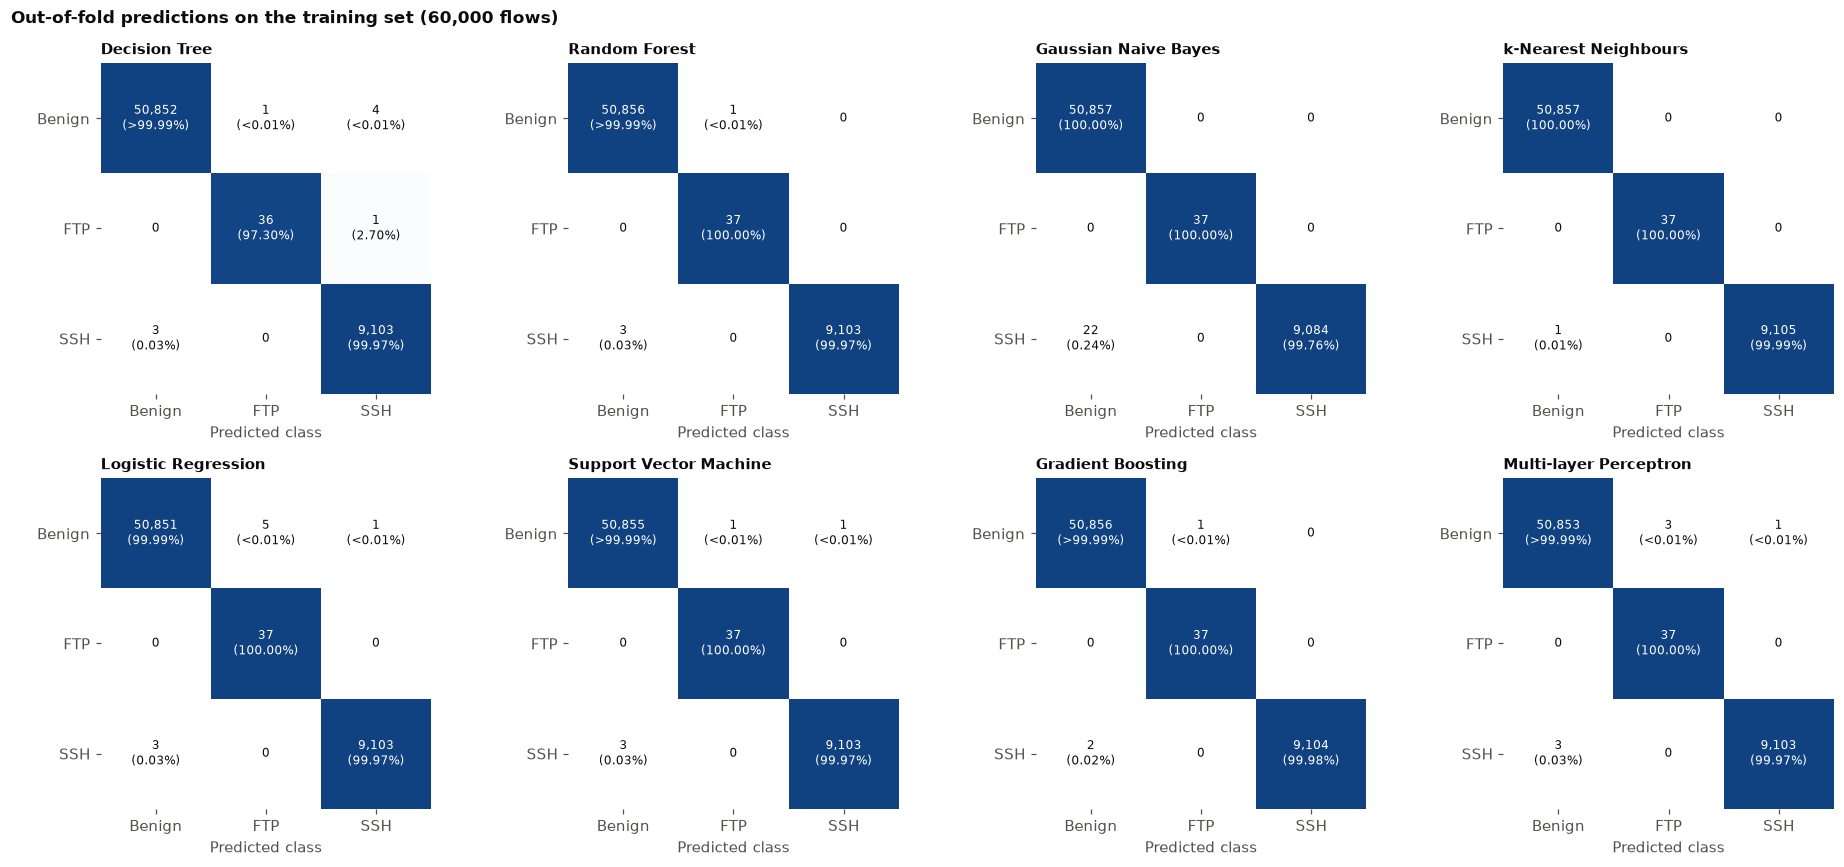

In [15]:
oof = {name: (y_train.to_numpy(), models.out_of_fold_predictions(run, X_train, y_train))
       for name, run in runs.items()}
fig = plotting.plot_confusion_matrices(oof, "Out-of-fold predictions on the training set (60,000 flows)")
plotting.save_figure(fig, "4_2_confusion_matrices_out_of_fold")

errors = pd.DataFrame([
    {"model": name, "true": t, "predicted": p, "flows": int(((yt == t) & (yp == p)).sum())}
    for name, (yt, yp) in oof.items() for t in plotting.CLASS_ORDER for p in plotting.CLASS_ORDER if t != p
])
errors = errors[errors["flows"] > 0]
errors.to_csv(config.TABLES_DIR / "4_2_out_of_fold_errors.csv", index=False)
(errors.pivot_table(index="model", columns=["true", "predicted"], values="flows", fill_value=0)
       .reindex(models.MODEL_NAMES).fillna(0).astype(int))

Are the SSH flows predicted as Benign the same flows for most models? If so, the difficulty lies in the flows.

In [16]:
missed_ssh = pd.Series(
    [i for yt, yp in oof.values() for i in np.flatnonzero((yt == "SSH-Bruteforce") & (yp == "Benign"))]
).value_counts()
hard_ssh = missed_ssh[missed_ssh >= len(oof) - 1].index.tolist()
print(f"SSH flows predicted as Benign by at least {len(oof) - 1} of the {len(oof)} models: {len(hard_ssh)}")
X_train.iloc[sorted(hard_ssh)][["Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts",
                                "TotLen Fwd Pkts", "Fwd Pkt Len Max", "Init Fwd Win Byts"]]

SSH flows predicted as Benign by at least 7 of the 8 models: 2


,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,Fwd Pkt Len Max,Init Fwd Win Byts
39040,6.0,12.0,1.0,1.0,0.0,0.0,241.0
41603,6.0,18501.0,2.0,0.0,0.0,0.0,241.0


## **Save the numbers quoted in the report** (`reports/numbers.json`)

In [17]:
def english_list(names):
    names = list(names)
    return "" if not names else names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]


kfold_range = composition.loc["KFold (shuffled)", ["min", "max"]].astype(int).tolist()
strat_range = composition.loc["StratifiedKFold (shuffled)", ["min", "max"]].astype(int).tolist()
macro_sd = splitter_table[splitter_table["metric"] == "f1_macro"].set_index("splitter")["std"]
t, tie, gvr = timing.set_index("model"), ties.set_index("model"), grid_vs_random
fastest_fit, slowest_fit = t["fit_seconds"].idxmin(), t["fit_seconds"].idxmax()
fastest_pred, slowest_pred = t["predict_ms_per_1000"].idxmin(), t["predict_ms_per_1000"].idxmax()
macro_base = {name: baseline[name]["test_f1_macro"].mean() for name in models.MODEL_NAMES}
macro_tuned = {name: summaries[name].loc["f1_macro", "validation_mean"] for name in models.MODEL_NAMES}
weighted = {name: summaries[name].loc["f1_weighted", "validation_mean"] for name in models.MODEL_NAMES}
total_errors = errors.groupby("model")["flows"].sum().reindex(models.MODEL_NAMES).fillna(0).astype(int)
best_macro, worst_macro = max(macro_tuned, key=macro_tuned.get), min(macro_tuned, key=macro_tuned.get)
improved = [m for m in models.MODEL_NAMES if macro_tuned[m] > macro_base[m] + 0.001]
worse = [m for m in models.MODEL_NAMES if macro_tuned[m] < macro_base[m] - 0.001]
largest_gap = overfit["gap"].idxmax()

In [18]:
report_numbers.record(
    kfold_ftp_range=f"{kfold_range[0]}–{kfold_range[1]}", strat_ftp_range=f"{strat_range[0]}–{strat_range[1]}",
    kfold_sd=f"{macro_sd['KFold (shuffled)']:.4f}", strat_sd=f"{macro_sd['StratifiedKFold (shuffled)']:.4f}",
    tree_scaling_agreement=f"{same:.2%}", tree_scaling_valid_rows=f"{len(X_val):,}",
    grid_fits=f"{gvr.loc['GridSearchCV', 'fits']:,}", grid_seconds=f"{gvr.loc['GridSearchCV', 'seconds']:.0f}",
    random_fits=f"{gvr.loc['RandomizedSearchCV', 'fits']:,}",
    random_seconds=f"{gvr.loc['RandomizedSearchCV', 'seconds']:.0f}",
    grid_best_weighted=f"{gvr.loc['GridSearchCV', 'best weighted F1']:.5f}",
    random_best_weighted=f"{gvr.loc['RandomizedSearchCV', 'best weighted F1']:.5f}",
    fit_fastest=f"{fastest_fit} ({t.loc[fastest_fit, 'fit_seconds']:.2f} s)",
    fit_slowest=f"{slowest_fit} ({t.loc[slowest_fit, 'fit_seconds']:.2f} s)",
    predict_fastest=f"{fastest_pred} ({t.loc[fastest_pred, 'predict_ms_per_1000']:.2f} ms)",
    predict_slowest=f"{slowest_pred} ({t.loc[slowest_pred, 'predict_ms_per_1000']:.2f} ms)",
    ties_models=f"{int((tie['settings within 1 SD'] >= 5).sum())}",
    cv_weighted_min=f"{min(weighted.values()):.4f}", cv_weighted_max=f"{max(weighted.values()):.4f}",
    cv_macro_worst=f"{worst_macro} ({macro_tuned[worst_macro]:.4f})",
    cv_macro_best=f"{best_macro} ({macro_tuned[best_macro]:.5f})",
    oof_errors_min=f"{total_errors.idxmin()} ({total_errors.min()})",
    oof_errors_max=f"{total_errors.idxmax()} ({total_errors.max()})",
    hard_ssh=f"{len(hard_ssh)}", overfit_largest=f"{largest_gap} ({overfit.loc[largest_gap, 'gap']:.4f})",
    tuning_improved=english_list(improved) or "no model", tuning_worse=english_list(worse) or "no model",
)

{'kfold_ftp_range': '4–9',
 'strat_ftp_range': '7–8',
 'kfold_sd': '0.0070',
 'strat_sd': '0.0090',
 'tree_scaling_agreement': '100.00%',
 'tree_scaling_valid_rows': '12,000',
 'grid_fits': '2,160',
 'grid_seconds': '494',
 'random_fits': '100',
 'random_seconds': '20',
 'grid_best_weighted': '0.99987',
 'random_best_weighted': '0.99985',
 'fit_fastest': 'k-Nearest Neighbours (0.27 s)',
 'fit_slowest': 'Multi-layer Perceptron (7.03 s)',
 'predict_fastest': 'Decision Tree (0.37 ms)',
 'predict_slowest': 'k-Nearest Neighbours (32.73 ms)',
 'ties_models': '8',
 'cv_weighted_min': '0.9996',
 'cv_weighted_max': '1.0000',
 'cv_macro_worst': 'Logistic Regression (0.9793)',
 'cv_macro_best': 'k-Nearest Neighbours (0.99998)',
 'oof_errors_min': 'k-Nearest Neighbours (1)',
 'oof_errors_max': 'Gaussian Naive Bayes (22)',
 'hard_ssh': '2',
 'overfit_largest': 'Decision Tree (0.0096)',
 'tuning_improved': 'k-Nearest Neighbours, Logistic Regression, Support Vector Machine and Gradient Boosting',
 't